In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys

from sklearn.model_selection import train_test_split
from sklearn import metrics

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
import statsmodels.api as sm


from sklearn.metrics import accuracy_score, balanced_accuracy_score,average_precision_score, precision_recall_curve, recall_score, precision_score, f1_score, fbeta_score
from sklearn.metrics import confusion_matrix, classification_report, make_scorer
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score, auc
import scikitplot as skplt

from joblib import load

import shap
from sklearn.inspection import partial_dependence, PartialDependenceDisplay


### Constantes:
seed=123


import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 500)
pd.set_option('display.max_rows', 500)

In [39]:
logistic_model = load('../modelos/regresionlog.joblib')

df_test = pd.read_csv('../data/processed_data/df_test_scaled.csv')
y_test = df_test['TARGET']
x_test = df_test.drop('TARGET', axis=1)

logistic_model

LogisticRegression(C=0.9, l1_ratio=0.24, max_iter=1000, penalty='l1',
                   random_state=123, solver='saga')

# Resultados

In [40]:
## Saco las predicciones de mi modelo para el conjunto de test
y_pred = logistic_model.predict(x_test)

## Sacamos las predicciones probabilísticas de cada instancia 
y_proba = logistic_model.predict_proba(x_test)

In [23]:
## Métricas básicas
f2score = fbeta_score(y_test, y_pred, beta=2)
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(accuracy)
print(f2score)
print(recall)

0.8122368014568395
0.36467586162343746
0.4547834843907351


Confusion matrix, without normalization
[[47697  8841]
 [ 2707  2258]]
Normalized confusion matrix
[[0.84362729 0.15637271]
 [0.54521652 0.45478348]]


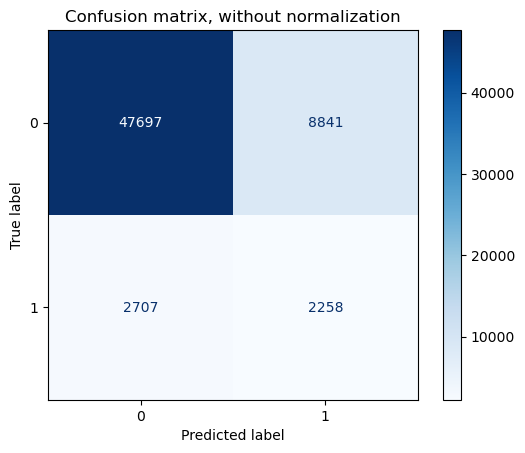

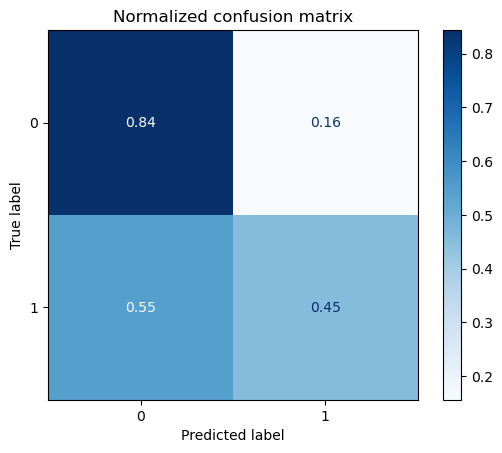

In [41]:
# Plot non-normalized confusion matrix
titles_options = [("Confusion matrix, without normalization", None),
                  ("Normalized confusion matrix", 'true')]

for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(logistic_model, x_test, y_test,
                                 # display_labels=ytest,
                                 cmap=plt.cm.Blues,
                                 normalize=normalize)
    disp.ax_.set_title(title)

    print(title)
    print(disp.confusion_matrix)

plt.show()

## Curva Roc

La curva ROC (Receiver Operating Characteristic) sirve para evaluar el desempeño de un modelo de clasificación binaria al mostrar la relación entre la tasa de verdaderos positivos (sensibilidad) y la tasa de falsos positivos a medida que se varía el umbral de decisión. Su propósito fundamental es analizar cómo de bien un modelo puede discriminar entre las dos clases (positiva y negativa) y ayudar a seleccionar el umbral de decisión más adecuado dependiendo de los objetivos del problema.

La curva ROC es especialmente útil en problemas donde existe un compromiso entre los errores que un modelo puede cometer: incrementar los aciertos en una clase (verdaderos positivos) suele implicar aceptar más errores en la otra clase (falsos positivos). Esta herramienta permite visualizar ese **trade-off** para tomar decisiones informadas.

Best Threshold=0.359511, G-Mean=0.670


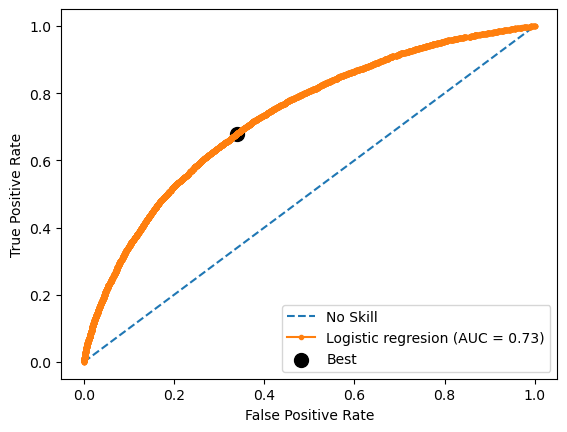

In [42]:
## Probabilidad de clase 1 -- Lo voy a usar para la mayoria de gráficas
# Extraemos las probabilidades predichas para la clase positiva (1). 
y_hat = y_proba[:,1]  

## Curva ROC
# Calculamos los puntos de la curva ROC: tasas de falsos positivos (FPR), verdaderos positivos (TPR) y los umbrales correspondientes.
fpr, tpr, thresholds = roc_curve(y_test, y_hat)

## Métrica G-Mean
# Calculamos la media geométrica (G-Mean) para evaluar el balance entre TPR y FPR en cada umbral.
gmeans = np.sqrt(tpr * (1-fpr))

# Determinamos el índice del umbral donde la G-Mean es máxima (punto óptimo).
ix = np.argmax(gmeans)
print('Best Threshold=%f, G-Mean=%.3f' % (thresholds[ix], gmeans[ix]))

# Área bajo la curva
roc_auc = roc_auc_score(y_test, y_hat)

plt.plot([0,1], [0,1], linestyle='--', label='No Skill')    ## Caso de aleatoriedad
plt.plot(fpr, tpr, marker='.', label=f'Logistic regresion (AUC = {roc_auc:.2f})') 

plt.scatter(fpr[ix], tpr[ix], s=100, marker='o', color='black', label='Best')

# labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
# show the plot
plt.show()

En el gráfico ROC se observa el rendimiento del modelo en términos de la tasa de verdaderos positivos (TPR) frente a la tasa de falsos positivos (FPR) para diferentes umbrales. Aunque inicialmente nuestro dataset estaba desbalanceado, tras ajustarlo a un 37.5% de clase minoritaria, hemos conseguido un rendimiento con un AUC de 0.73. Este valor sugiere que el modelo tiene una capacidad razonable para distinguir entre las clases positiva y negativa, aunque no alcanza un nivel excelente.

El análisis ha identificado un umbral óptimo en 0.379, en el cual se maximiza la media geométrica (G-Mean), alcanzando un valor de 0.669. Este punto óptimo nos indica el umbral a partir del cual la ganancia en la tasa de verdaderos positivos (TPR) comienza a ser menor que el incremento en la tasa de falsos positivos (FPR). En otras palabras, más allá de este umbral, el modelo empieza a perder eficiencia en la discriminación de clases, ya que aumentar la sensibilidad implica un costo desproporcionado en términos de falsos positivos.

Sin embargo, aunque hayamos usado técnias de 'resampleo' debemos señalar que la curva ROC no es ideal para datasets desbalanceados. En estos casos, métricas como la Precision-Recall (PR) son más informativas, ya que se centran específicamente en la capacidad del modelo para manejar la clase minoritaria. Por lo tanto, aunque la ROC nos da una visión general y aunque da unos resultados razonables, es necesario usar métricas como la Precision-Recall (PR) que son más informativas, ya que se centran específicamente en la capacidad del modelo para manejar la clase minoritaria

# Precision/Recall Curve 

La curva Precision-Recall (PR) es una herramienta gráfica que utilizo para evaluar el rendimiento de un modelo de clasificación binaria, especialmente útil en datasets desbalanceados. Representa la relación entre la precisión (proporción de predicciones correctas entre todas las predicciones positivas) y el recall (proporción de verdaderos positivos detectados entre todos los positivos reales) a lo largo de diferentes umbrales de decisión.
**Esto significa que nos muestra el 'trade-off' del entre ser capaz de identificar los casos positivos en función de cuanto está fallando el modelo.**

Esta curva es particularmente adecuada cuando quiero priorizar la clase minoritaria, ya que permite analizar cómo el modelo se comporta en términos de precisión y capacidad de detección de los positivos reales. A diferencia de la curva ROC, que utiliza la tasa de falsos positivos, la curva PR se centra únicamente en el rendimiento de la clase positiva.

Importante, en el código sustituyo los valores de Beta directamente y lo dejos simplificado, inicialmente lo he hehco así para ver como variaba el punto óptimo en función de beta, pero me ha parecido mejor dejarlo así porque, en base lo que he leido, la mejor métrica para casos desbalanceados binarios es B = 2. (Dejé link un link en la evaluación del notebook 3)
<center>

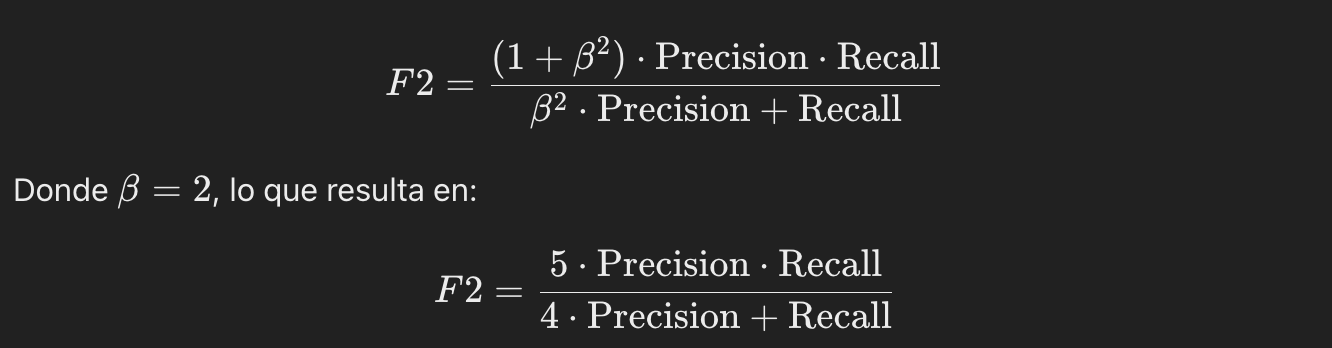
</center>

Best Threshold=0.338746, F2-Score=0.398


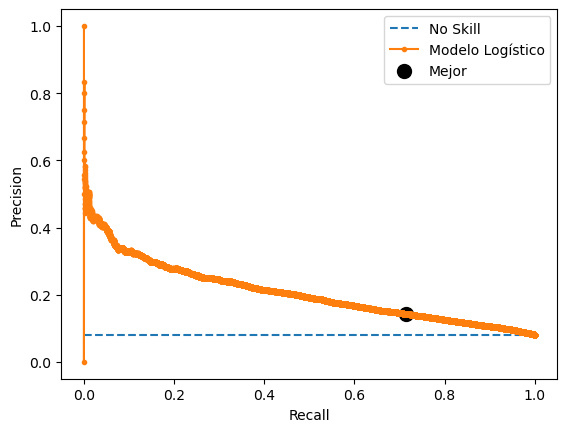

In [44]:
# calcular la curva Precision-Recall
precision, recall, thresholds = precision_recall_curve(y_test, y_hat)

# calcular la línea de "No Skill" (precisión base)
no_skill = len(y_test[y_test == 1]) / len(y_test)

# Evitar división por cero en el cálculo del F2-score
denominator = (4 * precision + recall)
f2_score = np.where(denominator > 0, (5 * precision * recall) / denominator, 0)

# localizar el índice del mayor F2-score
ix_f2 = np.argmax(f2_score)
print('Best Threshold=%f, F2-Score=%.3f' % (thresholds[ix_f2], f2_score[ix_f2]))

# graficar la curva Precision-Recall para el modelo
plt.plot([0, 1], [no_skill, no_skill], linestyle='--', label='No Skill')  # Línea base
plt.plot(recall, precision, marker='.', label='Modelo Logístico')       # Curva PR

# marcar el mejor punto F2 en la gráfica
plt.scatter(recall[ix_f2], precision[ix_f2], s=100, marker='o', color='black', label='Mejor')

# etiquetas de los ejes
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
# mostrar la gráfica
plt.show()


El punto óptimo identificado está en un umbral de 0.3927, donde el modelo alcanza un F2-Score de 0.397. Este valor del umbral maximiza el F2-Score, que prioriza el recall sobre la precisión (β=2), asegurando que el modelo identifique la mayor cantidad posible de verdaderos positivos sin sacrificar en exceso la precisión. 

Ya que considero esta métrica la más relevante, por su capacidad de maximizar el recall y su sencillez. Voy a realizar una matriza de confusión para poder comprender con más detalle que es lo que implica esto. Como ya he comentado, esta gráfica, y las demás, son una herramienta útil para ver el 'trade-off', lo que ganamos a cambio de lo que perdemos pero no nos da unos resultados tan 'tangibles' como nos lo puede dar la matriz.

Confusion matrix, without normalization
[[35437 21101]
 [ 1419  3546]]
Normalized confusion matrix
[[0.62678199 0.37321801]
 [0.2858006  0.7141994 ]]


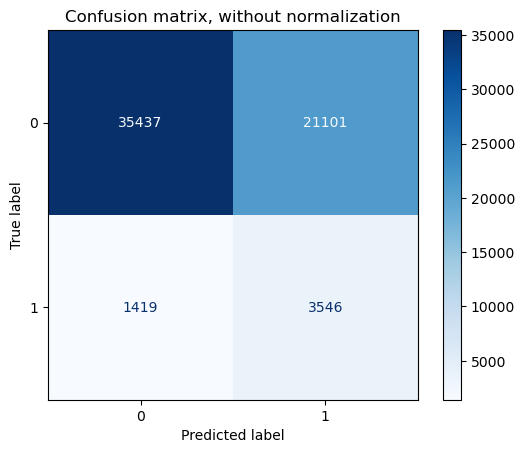

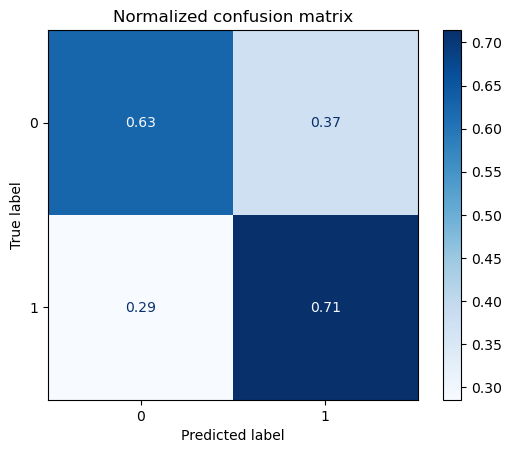

In [45]:
# Determino el umbral
threshold = thresholds[ix_f2]  
y_pred_f2 = (y_hat >= threshold).astype(int)

# Calcular la matriz de confusión usando las predicciones ajustadas
titles_options = [("Confusion matrix, without normalization", None),
                  ("Normalized confusion matrix", 'true')]

for title, normalize in titles_options:
    cm = confusion_matrix(y_test, y_pred_f2, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap=plt.cm.Blues)
    disp.ax_.set_title(title)

    print(title)
    print(cm)

plt.show()

La verdad que lo resultados de este cambio han sido muy buenos. Hemos aumentado consideramente la predicción de la clase positiva, en unos 18 puntos porcentuales, sacrificando la clase solo 13 aproximadamente de la clase minoritaria. Estamos consiguieno mejorar nuestro objetivo, predecir 'y = 1' sacrificando menos de lo que ganamos.

Hemos conseguido una mejora de 1.38 (en relación con la ganancia y perdida 18/13) en las predicciones del modelo, esto no exactamente así ya que al haber más clases 0 que 1, un aumento de 1% de en predeciendo la clase mayoritaria implica una mejor predicción en términos agragados. Pero esta ganancia relativa que hemos tenido nos ayuda a predecir de una forma que empieza a ser consistente los casos de posible impago. 

Este umbral sería muy intersante plantearlo a la hora de desarrollar el modelo final ya que consigue un balanceo que en términos de costes para un banco puede ser mejor. No hay que olvidar que se clasifica a demasiada gente con posibilidad de insolvencia, esto lo desarrollaré al final

# Gain Curve y Lift Curve

La gain curve y la lift curve son herramientas utilizadas para evaluar el rendimiento de modelos de clasificación, especialmente en problemas donde la prioridad es identificar correctamente la clase positiva. Aunque están relacionadas, tienen diferencias sutiles en cómo presentan la información.

- Gain curve: Muestra el porcentaje acumulado de la clase positiva que el modelo captura al analizar un porcentaje acumulado de las observaciones clasificadas con las probabilidades más altas. En el eje X se representa el porcentaje acumulado de las observaciones, y en el eje Y, el porcentaje acumulado de la clase positiva. Una curva ideal se eleva rápidamente, indicando que el modelo captura la mayoría de los positivos en un pequeño subconjunto de las instancias.

- Lift curve: Representa la mejora que el modelo proporciona en comparación con una selección aleatoria. Se calcula dividiendo la proporción de positivos identificados en un subconjunto del modelo por la proporción de positivos en una selección aleatoria. En el eje X se representa el porcentaje acumulado de la población, y en el eje Y, el lift, que indica cuántas veces el modelo mejora la detección de la clase positiva frente a la aleatoriedad.

No estoy seguro que la clase 0 se esté graficando bien, por lo que he visto, puede tener cierto sentido sobretodo en caso desbalanceados como este. Si bien tiene cierto sentido que la curva de la clase 0 esté cerca de la línea base en un caso desbalanceado, esto debe interpretarse con cuidado. En datasets donde la clase negativa (0) es mayoritaria, el modelo puede capturar un gran porcentaje de los negativos simplemente clasificando de forma aleatoria o ligeramente sesgada hacia la clase mayoritaria. 

En cuanto a la clase minoritaria, se observa que la mayor parte de la mejora en la detección ocurre en el primer 35% de los datos analizados, donde el modelo captura aproximadamente un 65% de los casos positivos acumulados. Este comportamiento indica que el modelo es particularmente efectivo al clasificar los ejemplos con mayores probabilidades predichas para la clase positiva, logrando una ganancia significativa en las primeras etapas de la curva. Sin embargo, a partir de este punto, la pendiente de la curva se reduce, lo que sugiere que el modelo tiene menos capacidad para diferenciar entre positivos y negativos en los datos restantes. Este resultado enfatiza la importancia de priorizar las observaciones más relevantes en la toma de decisiones, ya que el modelo muestra su mayor valor predictivo en esta fracción inicial del conjunto de datos.

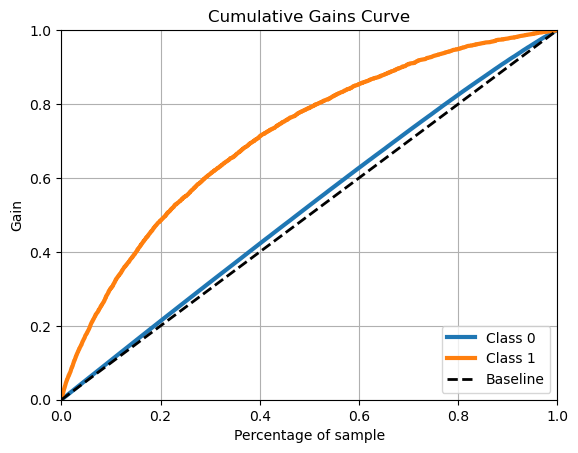

In [46]:
y_proba3 = logistic_model.predict_proba(x_test)[:, 1]
skplt.metrics.plot_cumulative_gain(y_test, y_proba)
plt.show()

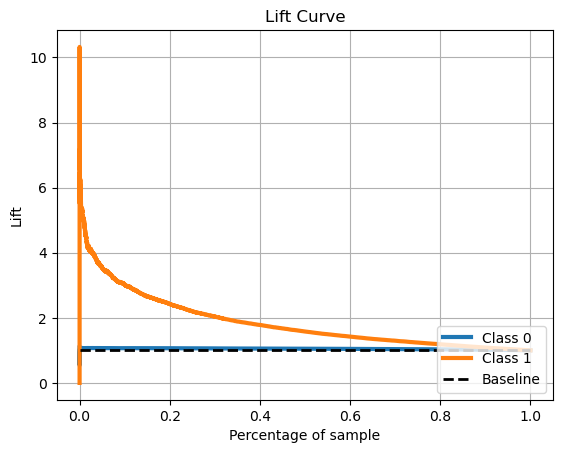

In [47]:
skplt.metrics.plot_lift_curve(y_test, y_proba)
plt.show()

# 4. - Explicabilidad - SHAP

SHAP (SHapley Additive exPlanations) es un método basado en la teoría de juegos para explicar las predicciones de modelos de machine learning. Es ampliamente utilizado en problemas donde es importante entender cómo las características individuales contribuyen a las predicciones de un modelo, especialmente en entornos complejos y modelos de tipo "caja negra" como árboles de decisión, modelos ensamblados (como Random Forest o XGBoost), y redes neuronales.

El objetivo es asignar a cada característica una contribución cuantitativa en la predicción de un modelo. Esto se hace descomponiendo la predicción como una suma de las contribuciones de las características individuales, más un valor base (el valor promedio de todas las predicciones posibles).

Se fundameneta en la siguiente fórmula matemática:
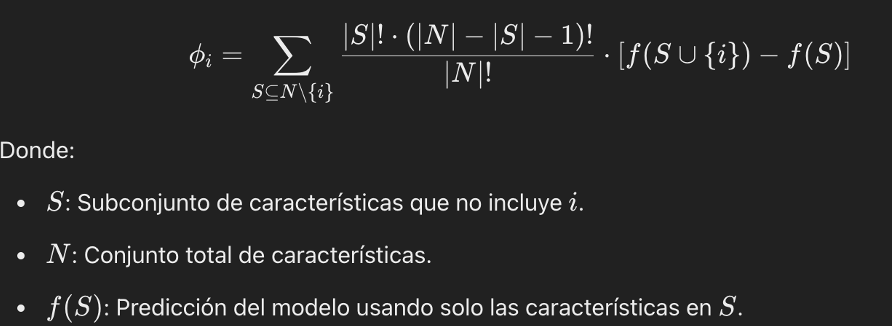

Una de las ventajas que ofrece esta librería es que nos puede dar información como veremos en los gráficos sobre explicación local y global.
- Explicación local: Para una observación específica, los valores SHAP muestran cómo cada característica influye positiva o negativamente en la predicción.
- Explicación global: Los valores promedio de SHAP en todo el dataset permiten identificar las características más importantes para el modelo.

(Información relevante: 'https://towardsdatascience.com/using-shap-values-to-explain-how-your-machine-learning-model-works-732b3f40e137')


In [48]:
# load JS visualization code to notebook
shap.initjs()
### Definimos como va a ser el explicador 
## explainer = shap.LinearExplainer(logistic_model.best_estimator_.named_steps['classifier'], x_test)

## Como lo he entrenado con los parámetros óptimos directamente, no tengo que buscar el mejor
explainer = shap.LinearExplainer(logistic_model, x_test)
print(explainer)
## creamos el explicador, aquí el dataset que le damos es para definir el explicador, en la siguiente celda
## es el dataset del que va a calcular los shap values
    ## podríamos calcular los valores shap de distintos datasets con el mismo explicador

## Calcula los valores shap de nuestro explicador par los variables independientes de validación
## The explainer variable will have three attributes: .values, .base_values and .data
##  - .dataattribute is simply a copy of the input data
##  - .base_values is the expected value of the target, or the average target value of all the train data
##  - .values are the SHAP values for each example
shap_values = explainer.shap_values(x_test)

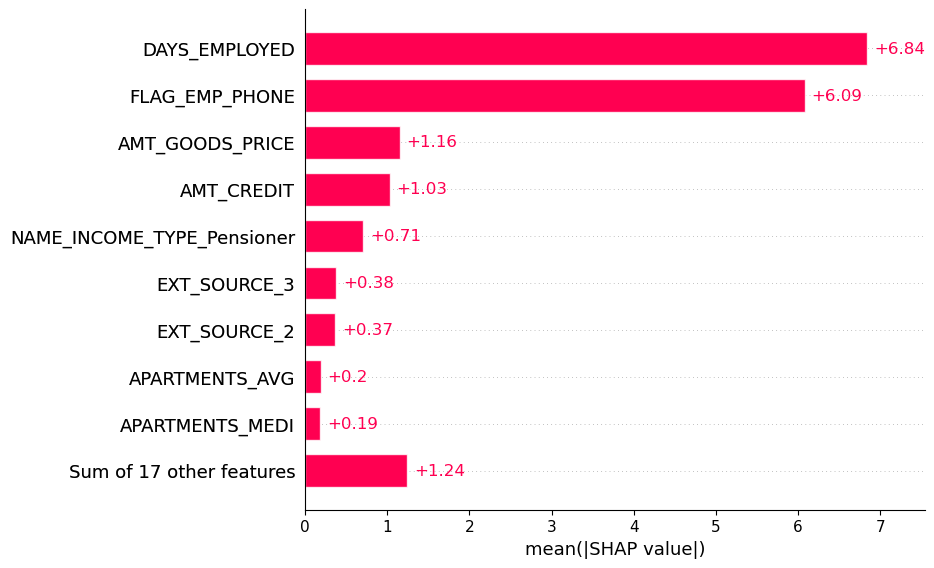

In [49]:
# shap.Explanation es una estructura de datos de SHAP que organiza la información necesaria para interpretar y visualizar los valores SHAP de un modelo.
# Combina los valores SHAP con datos adicionales como valores base, características originales
# y nombres de las mismas, proporcionando un formato estándar para la visualización y el análisis.

# Crear un objeto Explanation
shap_exp = shap.Explanation(
    values=shap_values,     ## valores SHAP
    base_values=explainer.expected_value,   ## Valore medio esperado antes de recibir ninguna caract.
    data=x_test,
    feature_names=x_test.columns
)

# Generar el gráfico de barras
shap.plots.bar(shap_exp)

En este gráfico, se calcula la magnitud promedio de los valores SHAP (en valor absoluto) para cada característica a lo largo del dataset. Esta magnitud representa la contribución promedio de cada característica al modelo, sin considerar si su impacto es positivo o negativo. El objetivo del gráfico es identificar de manera clara y visual cuáles son las características más influyentes en las predicciones globales del modelo.

Como podemos observar, la variable que tiene mayor impacto es ‘DAYS_EMPLOYED’, presentando más del doble de impacto medio que la siguiente variable. Esto indica que el modelo se basa principalmente en esta característica para realizar las predicciones, lo cual parece bastante coherente: una persona que ha trabajado durante muchos tiempo en el mismo trabajo tiene menos probabilidades de quedarse en paro a diferencia de alguien con menos experiencia laboral. Además, ha tenido más tiempo para generar ingresos, lo que, aunque no siempre se traduce en ahorro, también puede reflejar un nivel de responsabilidad.

Las siguientes variables que el modelo utiliza son: ‘FLAG_EMP_PHONE’, ‘AMT_GOODS_PRICE’, ‘AMT_CREDIT’ y ‘NAME_INCOME_TYPE_Pensioner’. Estas características tienen un impacto menor pero aún significativo. Están relacionadas con la cantidad de crédito solicitado, el valor de los bienes del cliente y su tipo de ingreso, proporcionando información complementaria clave para el modelo.

En conjunto, estas características permiten al modelo evaluar de manera razonable y entendible si un cliente tiene probabilidades de incurrir en impago, facilitando un análisis lógico que puede ser comunicado de forma clara a las partes interesadas.

# Partial Dependence Plots (PDP)

Los Partial Dependence Plots (PDP) son gráficos que muestran cómo cambia la predicción promedio de un modelo de machine learning cuando se varía una o más características de entrada, mientras se mantienen constantes las demás características. Su propósito principal es entender cómo una característica específica afecta el comportamiento general del modelo y su relación con la variable objetivo.

Estos gráficos permiten analizar el impacto de una característica en la predicción y determinar si esta tiene un efecto positivo o negativo en la variable objetivo, así como identificar posibles relaciones no lineales.

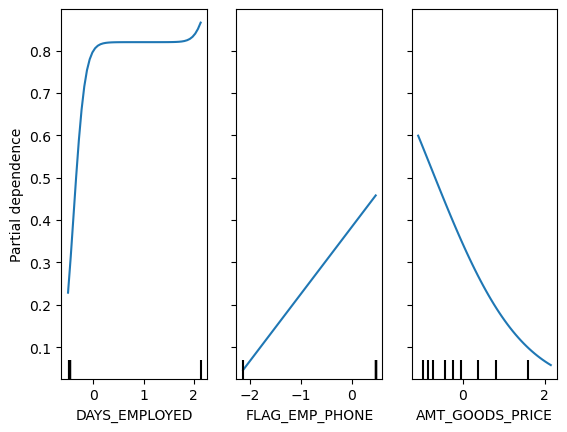

In [50]:
# PDP para una característica
PartialDependenceDisplay.from_estimator(
    logistic_model,
    x_test,
    ['DAYS_EMPLOYED', 'FLAG_EMP_PHONE', 'AMT_GOODS_PRICE'],  # Varias características
    grid_resolution=50
)

plt.show()

### **Según el modelo cuanto más tiemplo lleve el solicitante en su trabajo acutal, hay más probabilidades de impago, lo cual es muy raro.**

In [51]:
# Convertir shap_values a un objeto shap.Explanation
shap_exp = shap.Explanation(
    values=shap_values,                      # Valores SHAP (array de NumPy)
    base_values=explainer.expected_value,    # Valor base del modelo
    data=x_test,                             # Datos originales de entrada
    feature_names=x_test.columns             # Nombres de las características
)

print(type(shap_exp))

<class 'shap._explanation.Explanation'>


In [52]:
shap.force_plot(explainer.expected_value, shap_values[0], x_test.iloc[0,:])

**En una regresión logística binaria, expected_value es un escalar y no un vector. Esto sucede porque el modelo solo tiene una salida, correspondiente a la probabilidad de la clase positiva**. Por tanto no necesio específicar el que número de valor esperado cojo, si fuera
un árbol de decisión el modelo puede manejar múltiples salidas o clases en una clasificación multiclase. Por esta razón, expected_value es un vector que contiene un valor base para cada clase. Cada valor base representa la predicción promedio de esa clase antes de que las características específicas ajusten el resultado. Tendriamos:
- expected_value[0] para la primera clase.
- expected_value[n] así para cadda posible clase.

En modelos con múltiples salidas (por ejemplo, clasificación multiclase), expected_value sería un vector que contiene un valor base para cada clase. En esos casos, necesitaría especificar el índice para seleccionar el valor base correspondiente a una clase específica (por ejemplo, [0] para la clase positiva en binaria o la primera clase en multiclase).

In [53]:
## shap_values[:100,:] --> de las primera 100 instancias -- Extrae los valores shap
## X_val.iloc[:100, :] --> solo pasamos la 100 primeras filas del df

shap.force_plot(explainer.expected_value, shap_values[:200,:], features=x_test.iloc[:200, :])

Aunque ambos gráficos expresan ideas similares sobre el impacto de las características en las predicciones del modelo, me centraré en el análisis individual, ya que ofrece una explicación más detallada y específica de cómo las características afectan la predicción para una observación concreta. Esto no significa que el gráfico global no sea relevante; de hecho, permite identificar patrones generales y tendencias en el dataset. Pero en la explicación me voy a centrar en el primero, simplemente señalar del general, que cuantos más casos hay, más se atenua el impacto de las variables de forma individual.

En estos gráficos podemos observar el impacto que tienen las variables en el modelo, pero con su direccionalidad, es decir, si su contribución incrementa o reduce la predicción final del modelo. Un ejemplo claro de esto es ‘DAYS_EMPLOYED’, que tiene un impacto significativo y positivo en la predicción, empujándola hacia valores más altos. Esto sugiere que el modelo asocia esta variable con un mayor riesgo o una mayor probabilidad de la clase objetivo. En este caso, ‘DAYS_EMPLOYED’ contribuye con un valor de 2.133, lo que indica su importancia como un factor clave para el modelo.

Por otro lado, las variables ‘FLAG_EMP_PHONE’, ‘NAME_INCOME_TYPE_Pensioner’ y ‘NAME_INCOME_TYPE_Work’ tienen contribuciones negativas, reduciendo la predicción final. Por ejemplo, ‘FLAG_EMP_PHONE’ disminuye la predicción en 2.133, mostrando que, según el modelo, la ausencia de un teléfono asociado al empleador puede estar relacionada con una menor probabilidad de la clase objetivo o un menor riesgo. De manera similar, otras variables como ‘NAME_INCOME_TYPE_Pensioner’ tienen un impacto menor, pero aún significativo en la reducción de la predicción.

Estos gráficos son útiles porque no solo muestran la magnitud de las contribuciones de las variables, sino también su dirección, lo que facilita entender cómo el modelo utiliza las características para tomar decisiones. En este caso, vemos un equilibrio entre las contribuciones positivas y negativas, donde el impacto significativo de ‘DAYS_EMPLOYED’ es parcialmente contrarrestado por otras variables, lo que lleva a una predicción final de -2.33. Este análisis permite una comprensión clara de cómo el modelo interpreta las características y cómo estas influyen en las decisiones finales, ofreciendo transparencia y explicabilidad al proceso de modelado.

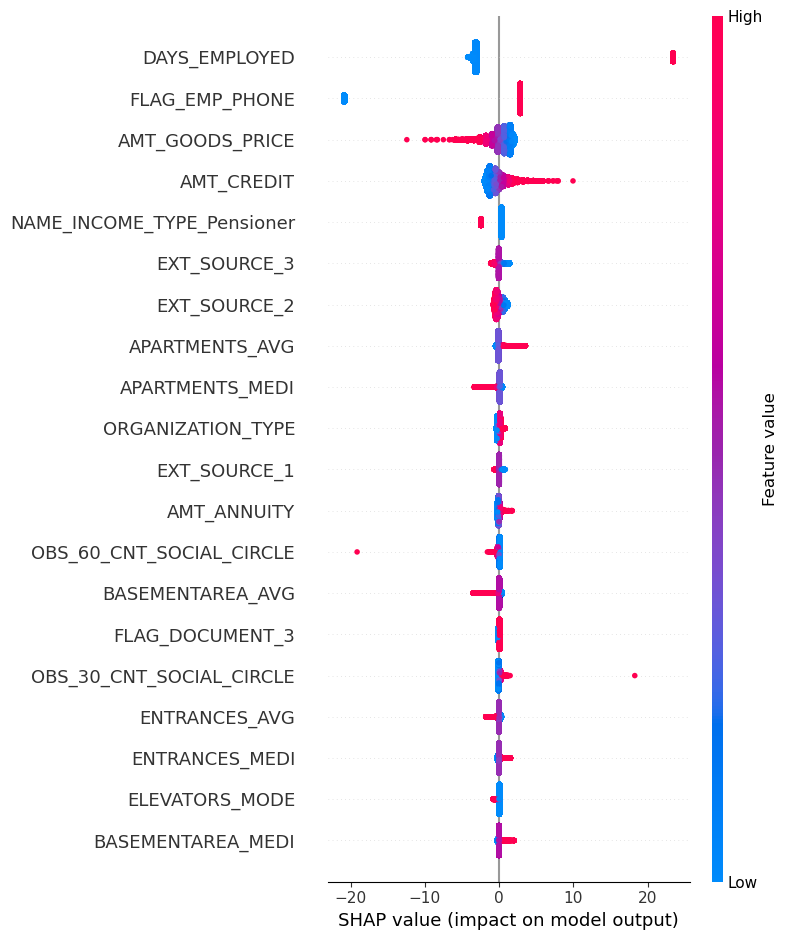

In [54]:
plt.rcParams.update({'ytick.labelsize': 8})  # Cambia el tamaño de las etiquetas en el eje Y
shap.summary_plot(shap_values, features=x_test)
# Si necesitas restaurar el tamaño original de la fuente para gráficos futuros:
plt.rcdefaults()


No voy a entrar demasiado en este gráfico ya que, con los análisis anteriores, hemos podido observar claramente el impacto diferenciado de las variables en el modelo. Sin embargo, es interesante comentar algunos casos concretos, como las variables EXT_SOURCE y ORGANIZATION_TYPE, que aportan perspectivas distintas pero complementarias en la toma de decisiones del modelo.

Las variables EXT_SOURCE representan puntuaciones externas relacionadas con el riesgo crediticio y suelen influir significativamente en las predicciones. Su valor radica en ser una medida objetiva y externa, que complementa la información interna del modelo. En general, valores altos de estas puntuaciones están asociados con una menor probabilidad de impago, lo que implica una contribución negativa en las predicciones del modelo. Por el contrario, valores bajos aumentan el riesgo percibido, mostrando un impacto positivo en las predicciones. Estas relaciones tienden a ser consistentes y proporcionan estabilidad en el análisis del modelo.

Por otro lado, ORGANIZATION_TYPE introduce un elemento más cualitativo, al clasificar al cliente según el tipo de empleador. Este factor puede estar relacionado con la estabilidad laboral y la capacidad de generar ingresos. Por ejemplo, categorías como "Gobierno" o "Educación" pueden asociarse con mayor estabilidad y, por ende, con menor riesgo. En contraste, categorías como "Asociado Comercial" o empleos en sectores más volátiles pueden incrementar el riesgo de impago. Importante tener en cuenta que esta era una variables categórica, y no tiene un orden específico por lo que, hay que tener cuidado con este caso.

# Conclusiones 

En este proyecto, he conseguido desarrollar un modelo de regresión logísica que es capaz de predecir de forma bastante consistente los casos de clientes fiables (84%) y los clientes no fiables en solo la mitad de los casos (45%). Esto, a mi parecer, no es lo suficientemente consistente para que un banco lo pueda utilizar, pero como primer proyecto son unos resultados válidos. 

Como hemos podido ver en la explicabilidad, el modelo se ha basado principalmente en una serie de parámetros para realizar las predicciones que resultan bastante intuitivos. Estos están relacionados con el tiempo que ha trabajado el cliente a lo largo de su vida y la cantidad de crédito solicitada. La  que más impacto produce en el modelo es: 'DAYS_EMPLOYED', esto tiene una cierta ventaja porque es una información de fácil acceso, y la cual el banco puede solicitarla al cliente de manera justificada.

Resulta llamativo que variables relacionadas con las valoraciones dadas a clientes, no sabemos por qué entidad, no las ha utilizado prácticamente. Esto no quiere decir que no sean buenas aproximaciones mismamentes, quizás simplemente nuestro modelo ha visto que por la otra vía lo podía predecir mejor. 

Como he comentado, no considero los resultados de este modelo suficientemente buenos como para una posible producción, esto nos lleva a 2 opciones. Por un lado, intentar mejorarlo, ya comenté en el apartado '3.4. - Evaluación modelos' del notebook 4 como se pueden mejorar generalmente. La mayoría de los métodos ya los he aplicado pero creo que aún se podría mejorar de las siguientes maneras: 

- Consiguieramos más datos, esto es la base del machine learning, cuantos más datos mejor. El dataset del que disponíamos es relativamente pequeño, una 300 mil filas, que teniendo en cuenta que un crédito es un instrumento financiero muy común, se puede solicitar para un coche, para una hipoteca,... aunque el crédito tenga una finalidad distinta, seguro que se puede extrapolar información para mejorar los resultados, ya que las variables que tenemos como importantes se deben presentar en la mayoría de las solicitudes de crédito, por lo menos de particulares.

- Volviendo a lo que es la selección de variables, y con la información que tenemos ahora de en que se basa nuestro modelo, probar otras combinaciones. Pero esto resulta bastante costoso en términos de tiempo y los niveles de mejora no espero que sean excesivamente elevados. 

- Generando nuevas variables. Esto lo podemos hacer a través de combinaciones lineales y no lineales de las ya existentes. Como queremos predecir la insolvencia podriamos, por ejemplo, crear: col_nueva1 = ('DAYS_EMPLOYED' * (1 - 'EXT_SOURCE_2')).

- Otra opción sería complementar el modelo con algún otro, como un modelo de IA generativa que realice un informe sobre el caso.

- También podríamos ajustar el umbral, como hemos visto anteriormente, para obtener mejores resultados, maximizando el F2-Score. Esta estrategia parece ser la única forma viable de mejorar el rendimiento de este modelo, ya que nos permitiría priorizar el recall sin comprometer excesivamente la precisión, logrando un balance más adecuado para nuestro objetivo.

Sin embargo, si no fuera posible mejorar significativamente el modelo mediante esta optimización, no sería recomendable implementarlo en producción. Un modelo que no cumpla con los estándares mínimos de rendimiento y que no sea capaz de aportar valor en el entorno real podría generar decisiones ineficientes o incluso contraproducentes.

